## Distinctive Service Patterns Across Repeated Courier-Days (Flag 6)

### Dataset Overview
The case contains 97 tasks and six Shanghai road-network trajectories. Availability and completion times allow pending-task exceptions to be inferred without answer-label fields.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Identify unusual or distinctive service patterns in repeated courier routes and explain how they differ from a straightforward one-stop–one-task process.

Role: Last-mile delivery operations analyst


Category: Courier Route Organization

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "orders.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Is there a task that was already available when the courier passed it, but was completed only after a much later return?

#### Analysis action

Compare availability time, first close GPS approach, and completion time for every task.

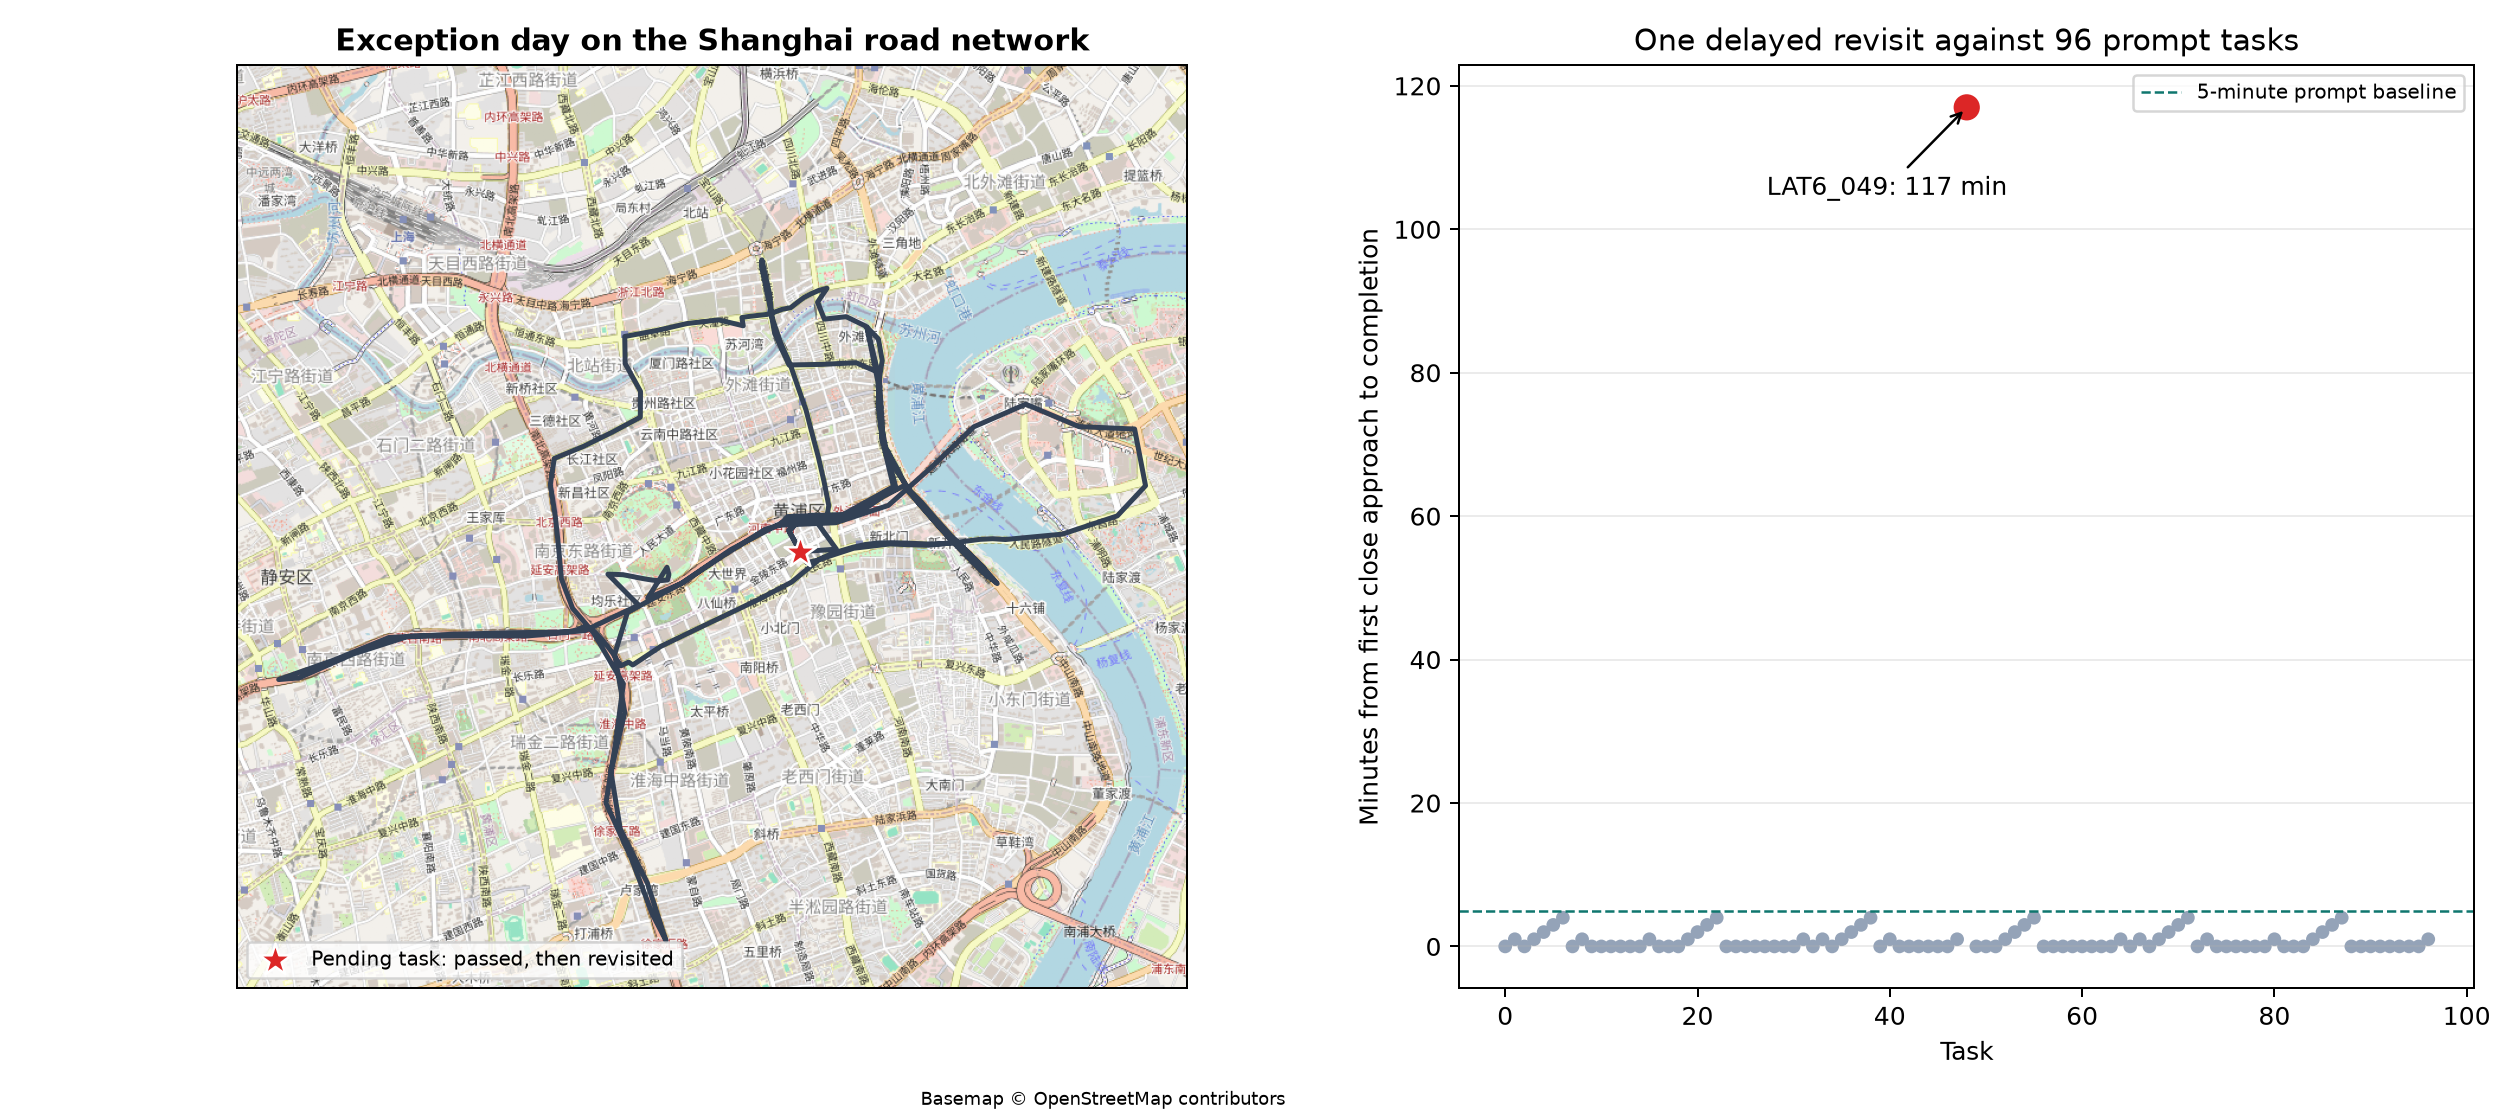

In [ ]:
import pandas as pd, numpy as np
o=df.copy(); t=user_df.copy()
o["available_time"]=pd.to_datetime(o.available_time); o["completion_time"]=pd.to_datetime(o.completion_time); t["gps_time"]=pd.to_datetime(t.gps_time)
def km(a,b,c,d):
 p1,p2=np.radians(b),np.radians(d);z=np.sin((p2-p1)/2)**2+np.cos(p1)*np.cos(p2)*np.sin(np.radians(c-a)/2)**2;return 6371.0088*2*np.arctan2(np.sqrt(z),np.sqrt(1-z))
rows=[]
for r in o.itertuples():
 q=t[(t.trajectory_id==r.trajectory_id)&(t.gps_time>=r.available_time)&(t.gps_time<=r.completion_time)].copy();q["distance"]=km(q.lng,q.lat,r.task_lng,r.task_lat);close=q[q.distance<=.08];first=close.iloc[0] if len(close) else q.loc[q.distance.idxmin()];rows.append((r.task_id,(r.completion_time-first.gps_time).total_seconds()/60))
print(pd.DataFrame(rows,columns=["task_id","delay_min"]).sort_values("delay_min",ascending=False).head())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/skipped_task_distance_timeline.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "distance_time_series",
  "insight_type": "exception_deviation",
  "insight": "The courier passes close to a pending task without completing it, leaves the area to serve several other tasks, and returns much later to complete the skipped delivery.",
  "insight_value": {
    "skipped_task": "LAT6_049",
    "exception_delay_minutes": 117.0,
    "normal_max_delay_minutes": 4.0
  },
  "plot": {
    "plot_type": "map_and_delay_distribution",
    "title": "Skipped Pending Task Against Prompt-Completion Baseline",
    "file": "visualizations/skipped_task_distance_timeline.png",
    "description": "The exception-day map is paired with first-approach-to-completion delays for all tasks."
  },
  "question": "Is there a task that was already available when the courier passed it, but was completed only after a much later return?",
  "actionable_insight": "Compare availability time, first close GPS approach, and completion time for every task.",
  "code": "import pandas as pd, numpy as np\no=df.copy(); t=user_df.copy()\no[\"available_time\"]=pd.to_datetime(o.available_time); o[\"completion_time\"]=pd.to_datetime(o.completion_time); t[\"gps_time\"]=pd.to_datetime(t.gps_time)\ndef km(a,b,c,d):\n p1,p2=np.radians(b),np.radians(d);z=np.sin((p2-p1)/2)**2+np.cos(p1)*np.cos(p2)*np.sin(np.radians(c-a)/2)**2;return 6371.0088*2*np.arctan2(np.sqrt(z),np.sqrt(1-z))\nrows=[]\nfor r in o.itertuples():\n q=t[(t.trajectory_id==r.trajectory_id)&(t.gps_time>=r.available_time)&(t.gps_time<=r.completion_time)].copy();q[\"distance\"]=km(q.lng,q.lat,r.task_lng,r.task_lat);close=q[q.distance<=.08];first=close.iloc[0] if len(close) else q.loc[q.distance.idxmin()];rows.append((r.task_id,(r.completion_time-first.gps_time).total_seconds()/60))\nprint(pd.DataFrame(rows,columns=[\"task_id\",\"delay_min\"]).sort_values(\"delay_min\",ascending=False).head())",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "task_position",
    "available_time",
    "completion_time",
    "gps_time",
    "gps_position",
    "task_id",
    "courier_id"
  ]
}

### **Question 2**: Does rapid completion of nearby tasks recur across independent courier-days?

#### Analysis action

Compare elapsed completion time and displacement within each day’s dense local batch.

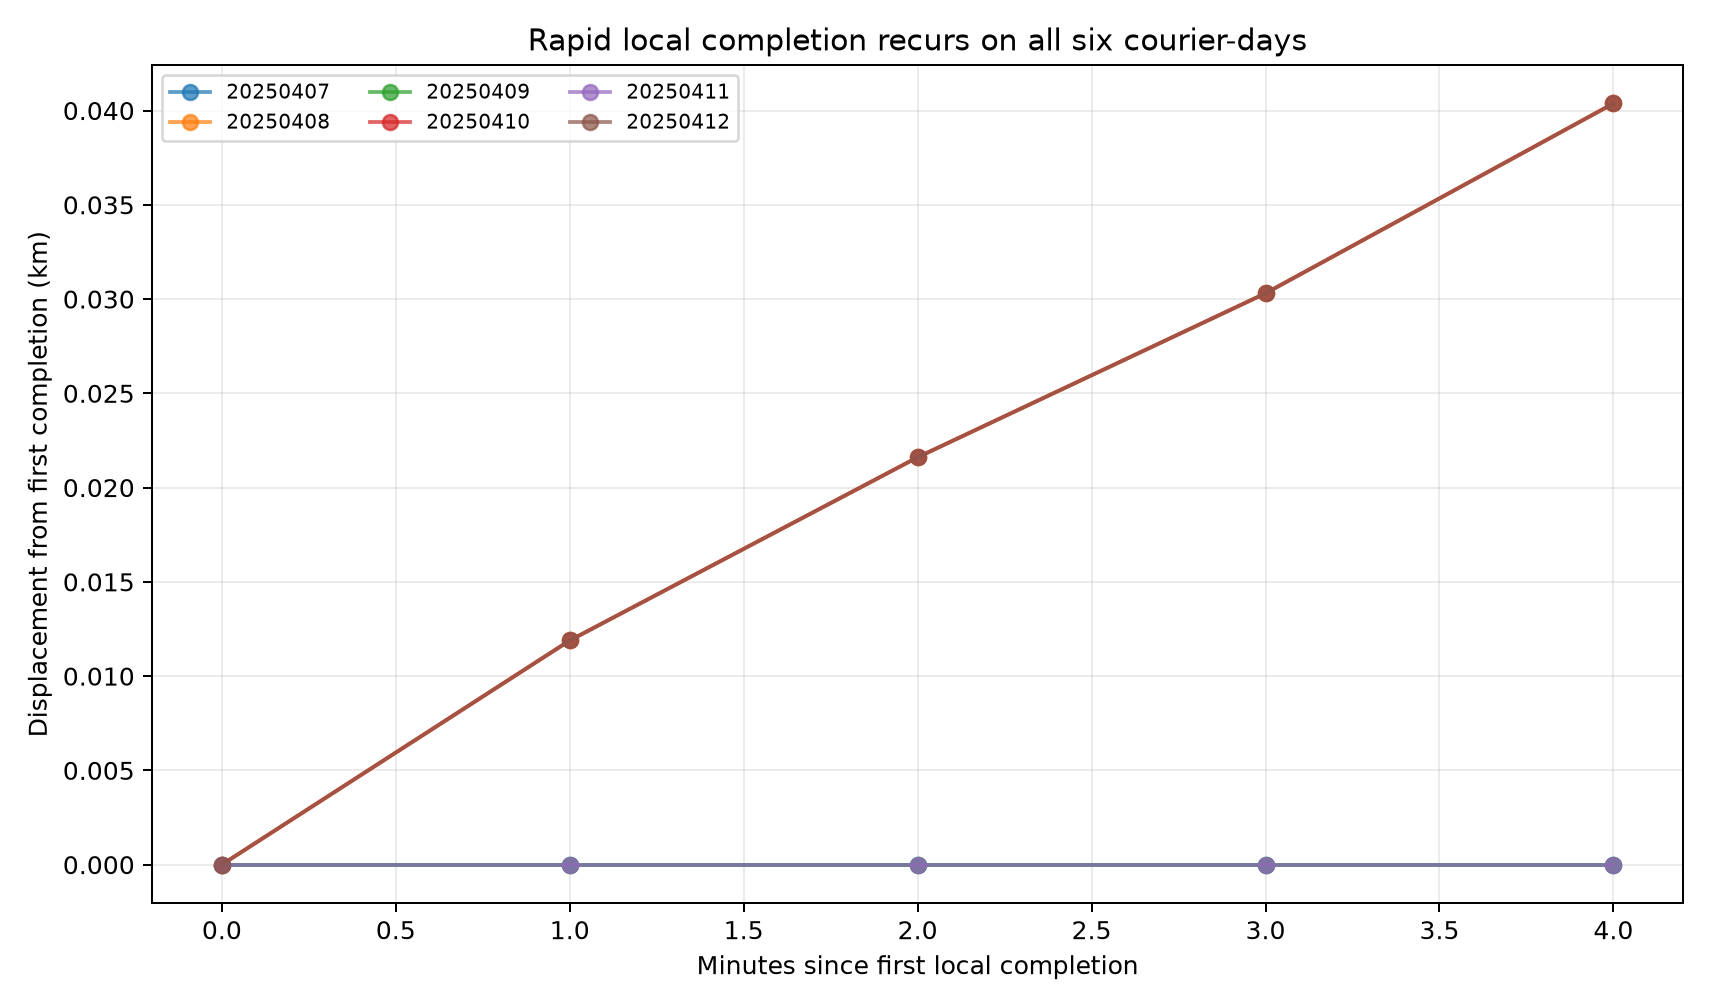

In [ ]:
import pandas as pd
d=df.copy();d["completion_time"]=pd.to_datetime(d.completion_time);q=d[(d.completion_time.dt.hour==9)&d.completion_time.dt.minute.between(40,44)];print(q.groupby("service_date").size())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/rapid_local_batch.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "local_completion_scatter",
  "insight_type": "temporal_dynamics",
  "insight": "Several nearby deliveries are completed within a short time interval while the courier’s recorded position changes very little.",
  "insight_value": {
    "courier_days": 6,
    "nearby_deliveries_per_day": 5,
    "completion_window_minutes": 4
  },
  "plot": {
    "plot_type": "repeated_local_profiles",
    "title": "Rapid Nearby Deliveries Across Courier-Days",
    "file": "visualizations/rapid_local_batch.png",
    "description": "Six day-level profiles show repeated rapid completions with limited displacement."
  },
  "question": "Does rapid completion of nearby tasks recur across independent courier-days?",
  "actionable_insight": "Compare elapsed completion time and displacement within each day’s dense local batch.",
  "code": "import pandas as pd\nd=df.copy();d[\"completion_time\"]=pd.to_datetime(d.completion_time);q=d[(d.completion_time.dt.hour==9)&d.completion_time.dt.minute.between(40,44)];print(q.groupby(\"service_date\").size())",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "task_position",
    "completion_time",
    "gps_time",
    "gps_position",
    "task_id",
    "courier_id"
  ]
}

### **Question 3**: Do independent courier-days progress steadily across areas, or repeatedly return to areas served earlier?

#### Analysis action

Inspect ordered service-area sequences and count returns to previously served areas.

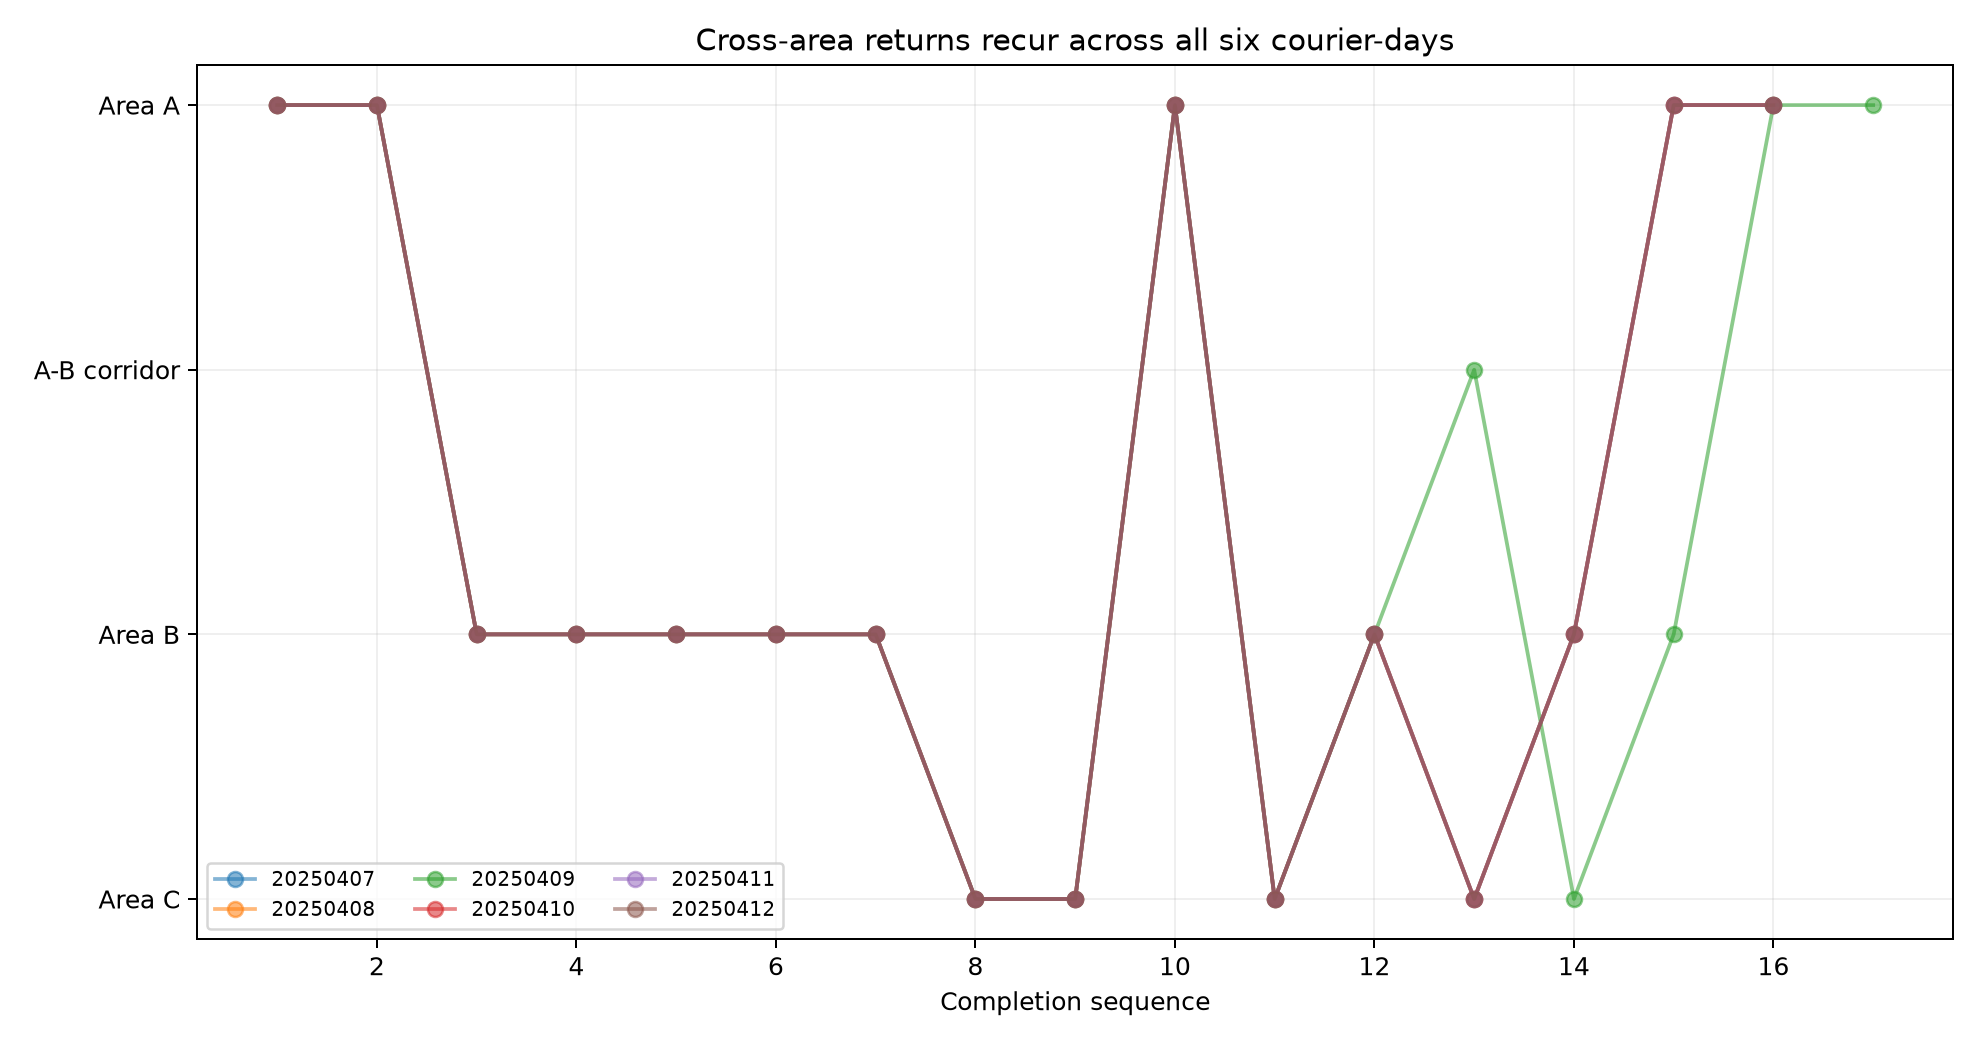

In [ ]:
d=df.sort_values(["service_date","completion_sequence"]);print(d.groupby("service_date").service_area.apply(list))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/fragmented_area_transitions.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "area_transition_sequence",
  "insight_type": "temporal_dynamics",
  "insight": "Instead of progressing steadily from one service area to the next, the courier repeatedly returns to previously visited areas, producing a fragmented route with several cross-area transitions.",
  "insight_value": {
    "courier_days": 6,
    "revisited_areas": [
      "A",
      "B",
      "C"
    ]
  },
  "plot": {
    "plot_type": "repeated_area_sequences",
    "title": "Fragmented Area Transitions Across Courier-Days",
    "file": "visualizations/fragmented_area_transitions.png",
    "description": "Completion-area sequences show repeated returns on all six days."
  },
  "question": "Do independent courier-days progress steadily across areas, or repeatedly return to areas served earlier?",
  "actionable_insight": "Inspect ordered service-area sequences and count returns to previously served areas.",
  "code": "d=df.sort_values([\"service_date\",\"completion_sequence\"]);print(d.groupby(\"service_date\").service_area.apply(list))",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "completion_time",
    "gps_position",
    "courier_id",
    "gps_time",
    "task_id"
  ]
}

### Summary of Findings (Flag 6)

Across six courier-days, rapid local batches and fragmented cross-area returns recur as normal patterns, while one already-available task is uniquely passed and completed only after a much later revisit.